# 03B 发送分集与空时分组码 (STBC) 仿真实验（学生版）

本实验参考《无线通信系统仿真》（25版）中的**“开放性综合实验三：多天线分集系统仿真”**之**“实验二：发送分集”**（教材第 38~52 页）。

## 1. 实验原理与教学目的

在很多实际通信场景中（如下行蜂窝通信），由于移动终端体积和功耗受限，很难在接收端安装多个天线。为了获得分集增益，可以在发射基站端部署多个天线，采用**发送分集（Transmit Diversity）**技术。发送分集的核心是**空时编码（Space-Time Coding, STC）**，其中最经典且兼具优雅正交解耦特性的就是**空时分组码（STBC, Space-Time Block Code）**。

### 1.1 1998 年 Alamouti 空时分组码（2 发 1 收，G2 码）
1998 年 S. Alamouti 提出了适用于双天线发射的正交空时分组码，能够在仅有 1 根接收天线的条件下提供 2 阶全分集增益，且编码速率为全速率 $R = 1$。
- **发射矩阵设计**：设连续两个符号周期的调制符号为 $x_1, x_2$，编码发射矩阵为：
  $$S = \begin{bmatrix} x_1 & x_2 \\ -x_2^* & x_1^* \end{bmatrix}$$
  在时刻 1：天线 1 发射 $x_1$，天线 2 发射 $x_2$；
  在时刻 2：天线 1 发射 $-x_2^*$，天线 2 发射 $x_1^*$。
  每根天线发射功率标定为 $1/\sqrt{2}$，保证总发射功率保持恒定。
- **正交解耦译码**：设天线 1 和 2 到接收端的平坦瑞利信道分别为 $h_1, h_2$。在相干时间内两个符号周期的接收信号为：
  $$r_1 = \frac{1}{\sqrt{2}}(h_1 x_1 + h_2 x_2) + n_1$$
  $$r_2 = \frac{1}{\sqrt{2}}(-h_1 x_2^* + h_2 x_1^*) + n_2$$
  接收端仅通过简单的线性正交组合运算即可完全解耦：
  $$\hat{x}_1 = \frac{h_1^* r_1 + h_2 r_2^*}{\frac{1}{\sqrt{2}}(|h_1|^2 + |h_2|^2)} = x_1 + \tilde{n}_1$$
  $$\hat{x}_2 = \frac{h_2^* r_1 - h_1 r_2^*}{\frac{1}{\sqrt{2}}(|h_1|^2 + |h_2|^2)} = x_2 + \tilde{n}_2$$
  各符号等效信噪比与信道模平方 $|h_1|^2 + |h_2|^2$ 成正比，实现了二阶最大似然分集检测而无需任何矩阵求逆！

### 1.2 高阶正交空时分组码与多天线扩展
- **3 发 1 收正交空时码 ($G_3$)**：教材第 49~50 页给出的 3 天线正交设计。采用 8 个时隙传输 4 个信息符号，码率为半速率 $R = 1/2$，实现严格的 3 阶发射分集。
- **2 发 2 收空间结合 ($2\times 2$ Alamouti)**：发送端采用 Alamouti 双天线编码，接收端采用双天线接收。总分集阶数达到 $2 \times 2 = 4$ 阶分集，在全速率传输下误码率斜率大幅陡峭化！

## 2. 实验参数与设计内容（对标教材第 47~52 页）
- **调制方式**：BPSK（$0 \to +1, 1 \to -1$）与 QPSK 扩展
- **天线配置与编码方案**：
  1. $1\times 1$ SISO：单发单收无分集基准
  2. $2\times 1$ Alamouti STBC ($G_2$ 码，全速率 $R=1$，二阶分集)
  3. $3\times 1$ STBC ($G_3$ 码，半速率 $R=1/2$，三阶分集)
  4. $2\times 2$ Alamouti STBC (2 发 2 收，全速率 $R=1$，四阶分集)
- **实验任务**：
  1. **模块一**：补全 Alamouti $2\times 1$ 编解码、3 发 1 收 $G_3$ 编解码以及 $2\times 2$ 空间结合译码器；
  2. **模块二（基本实验）**：完成不同空时分组码方案在平坦瑞利信道下的性能仿真（对标教材图 2.17），对比 SISO、$2\times 1$、$3\times 1$、$2\times 2$ 的 BER 曲线；
  3. **模块三（拓展实验）**：对比 QPSK 调制下 $2\times 1$ Alamouti 发送分集与 $1\times 2$ MRC 接收分集的性能差异。


In [1]:
# 模块一：环境准备与 STBC 空时编码核心组件实现
from pathlib import Path
import sys

# 从当前目录向上查找 src/sionna，优先使用本仓库源码。
for p in [Path.cwd(), *Path.cwd().parents]:
    if (p / "src" / "sionna").exists():
        sys.path.insert(0, str(p / "src"))
        break

import numpy as np
import torch
import matplotlib.pyplot as plt
import scipy.special as sp

# 设置 Matplotlib 中文字体，避免图标题和坐标轴中文乱码。
plt.rcParams["font.sans-serif"] = [
    "Microsoft YaHei",
    "SimHei",
    "Noto Sans CJK SC",
    "Arial Unicode MS",
    "DejaVu Sans",
]
plt.rcParams["axes.unicode_minus"] = False

# Word 报告中的图宽约 14.4 cm，插入时会被缩放，因此整体放大字号，
# 使打印后的字号与正文（10.5 pt）接近。
plt.rcParams.update(
    {
        "font.size": 13,
        "axes.labelsize": 13,
        "axes.titlesize": 13,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "legend.fontsize": 11,
        "figure.dpi": 200,
        "savefig.dpi": 200,
    }
)

# 固定使用 CPU，保证没有 GPU 的学生电脑也能运行。
DEVICE = "cpu"
PRECISION = "single"

# 固定随机种子，便于复现实验结果。
# 本实验的信道与噪声全部由 torch 直接产生（不用 sionna 的随机信道/噪声模块），
# 因此固定 torch / numpy 两个随机源即可保证两次运行结果完全一致。
torch.manual_seed(42)
np.random.seed(42)

# 图、数据输出目录：便于把过程性与结果性材料归档到同一文件夹。
FIG_DIR = Path.cwd() / "figures"
DATA_DIR = Path.cwd() / "data"
FIG_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)

INV_SQRT2 = float(1.0 / np.sqrt(2.0))   # Alamouti：每根天线功率除以 sqrt(2)
INV_SQRT3 = float(1.0 / np.sqrt(3.0))   # G3：每根天线功率除以 sqrt(3)


# ---------------------------------------------------------------------------
# 0) 复高斯随机量：零均值、单位方差（实部虚部各 1/2）的循环对称复高斯
# ---------------------------------------------------------------------------
def cnormal(*shape):
    """产生循环对称复高斯随机张量 CN(0, 1)。"""
    return (torch.complex(torch.randn(*shape), torch.randn(*shape)) * INV_SQRT2).to(
        torch.complex64
    )



# ---------------------------------------------------------------------------
# 1) BPSK 调制与硬判决解调
# ---------------------------------------------------------------------------
def bpsk_modulate(bits):
    """自主实现 BPSK 调制映射: 0 -> +1, 1 -> -1（符号能量 Es = 1）。

    输入 bits 为任意形状的 0/1 整数张量，输出同形状的 complex64 符号张量。
    统一用复数类型表示符号，可直接与前面推导的复基带信道模型对接。
    """
    return (1.0 - 2.0 * bits.to(torch.float32)).to(torch.complex64)


def bpsk_demodulate(symbols):
    """自主实现 BPSK 硬判决: 实数部分 < 0 判为 1，否则判为 0。

    译码器的输出是含噪软符号 x_hat = x + n_eff（x = +/-1 为实数符号），
    因此只需对实部做零门限判决即可。
    """
    return (torch.real(symbols) < 0).to(torch.int64)


# ---------------------------------------------------------------------------
# 2) Alamouti 2 发 1 收（G2 码，全速率 R = 1）
# ---------------------------------------------------------------------------
def alamouti_2x1_encode(x1, x2):
    """Alamouti 2 发 1 收空时编码 (G2 矩阵)。

    时刻 1: 天线 1 发 x1, 天线 2 发 x2
    时刻 2: 天线 1 发 -conj(x2), 天线 2 发 conj(x1)

    G2 码字矩阵 S = [[x1, x2], [-conj(x2), conj(x1)]]，两列（天线）相互正交，
    因此接收端无需矩阵求逆即可正交解耦。
    功率归一化: 每根天线功率除以 sqrt(2)，保证 2 个时隙总发射功率恒为 1。

    输入 x1, x2 形状 (N,)，输出 S[slot, antenna, :] 形状 (2, 2, N)。
    """
    slot1 = torch.stack([x1, x2], dim=0)                       # 时刻 1：两根天线
    slot2 = torch.stack([-torch.conj(x2), torch.conj(x1)], dim=0)  # 时刻 2
    return torch.stack([slot1, slot2], dim=0) * INV_SQRT2


def alamouti_2x1_decode(r1, r2, h1, h2):
    """Alamouti 2 发 1 收正交解耦译码（对标教材 lines 632~634）。

    接收信号（h1, h2 为两个发射天线到接收天线的平坦瑞利信道）：
        r1 = (1/sqrt2) * (h1*x1 + h2*x2)       + n1
        r2 = (1/sqrt2) * (-h1*conj(x2) + h2*conj(x1)) + n2
    正交组合（利用 |h1|^2 + |h2|^2 的公共归一化因子）：
        x1_hat = (conj(h1)*r1 + h2*conj(r2)) / ((1/sqrt2) * (|h1|^2 + |h2|^2))
        x2_hat = (conj(h2)*r1 - h1*conj(r2)) / ((1/sqrt2) * (|h1|^2 + |h2|^2))
    合并后 x1_hat = x1 + n_eff、x2_hat = x2 + n_eff，两路符号完全解耦，
    等效信噪比正比于 |h1|^2 + |h2|^2，因此获得 2 阶发射分集。
    """
    den = INV_SQRT2 * (h1.abs() ** 2 + h2.abs() ** 2)
    x1_hat = (torch.conj(h1) * r1 + h2 * torch.conj(r2)) / den
    x2_hat = (torch.conj(h2) * r1 - h1 * torch.conj(r2)) / den
    return x1_hat, x2_hat


# ---------------------------------------------------------------------------
# 3) Alamouti 2 发 2 收（空间结合，4 阶分集）
# ---------------------------------------------------------------------------
def alamouti_2x2_decode(r_rx1, r_rx2, h_rx1, h_rx2):
    """Alamouti 2 发 2 收空间结合译码 (4 阶分集)。

    r_rx1, r_rx2 形状 (2, N)：第 1/2 根接收天线在两个时隙的接收信号；
    h_rx1, h_rx2 形状 (2, N)：第 1/2 根接收天线到两个发射天线的信道。

    两根接收天线各自完成一次 2x1 正交解耦，再把两路同相合并（信道模平方加权），
    等效信噪比正比于 4 条收发链路的 |h|^2 之和，故分集阶数为 2 发 x 2 收 = 4。
    """
    h11, h12 = h_rx1[0], h_rx1[1]
    h21, h22 = h_rx2[0], h_rx2[1]
    ch_norm_sq = (
        h11.abs() ** 2 + h12.abs() ** 2 + h21.abs() ** 2 + h22.abs() ** 2
    )

    x1_hat = (
        torch.conj(h11) * r_rx1[0]
        + h12 * torch.conj(r_rx1[1])
        + torch.conj(h21) * r_rx2[0]
        + h22 * torch.conj(r_rx2[1])
    ) / (INV_SQRT2 * ch_norm_sq)
    x2_hat = (
        torch.conj(h12) * r_rx1[0]
        - h11 * torch.conj(r_rx1[1])
        + torch.conj(h22) * r_rx2[0]
        - h21 * torch.conj(r_rx2[1])
    ) / (INV_SQRT2 * ch_norm_sq)
    return x1_hat, x2_hat


# ---------------------------------------------------------------------------
# 4) 3 发 1 收 G3 正交空时分组码（半速率 R = 1/2）
# ---------------------------------------------------------------------------
def stbc_3x1_encode(x):
    """3 发 1 收 G3 正交空时分组码编码（教材第 49~50 页）。

    x 形状 (4, N)：一个 G3 码字内的 4 个调制符号。
    输出 S 形状 (8, 3, N)，S[slot, antenna, :]：8 个时隙 x 3 根天线。
    前 4 个时隙发送原符号，后 4 个时隙发送共轭符号，
    8 个时隙只传 4 个符号，因此码率为 R = 1/2。
    每根天线功率除以 sqrt(3)，保证每时隙总发射功率与单天线一致。
    """
    x1, x2, x3, x4 = x[0], x[1], x[2], x[3]
    c = torch.conj
    rows = [
        [x1, x2, x3],                       # 时隙 1
        [-x2, x1, -x4],                     # 时隙 2
        [-x3, x4, x1],                      # 时隙 3
        [-x4, -x3, x2],                     # 时隙 4
        [c(x1), c(x2), c(x3)],              # 时隙 5
        [-c(x2), c(x1), -c(x4)],            # 时隙 6
        [-c(x3), c(x4), c(x1)],             # 时隙 7
        [-c(x4), -c(x3), c(x2)],            # 时隙 8
    ]
    S = torch.stack([torch.stack(row, dim=0) for row in rows], dim=0)
    return S * INV_SQRT3


def stbc_3x1_decode(r_slots, h_vec):
    """3 发 1 收 G3 正交空时分组码译码（对标教材 lines 685~694）。

    r_slots 形状 (8, N) 为 8 个时隙的接收信号，h_vec 形状 (3, N) 为 3 根发射
    天线到接收天线的信道。按教材给出的正交组合公式直接恢复 4 个符号：

        x1_hat = (conj(h1)r1 + conj(h2)r2 + conj(h3)r3
                  + h1*conj(r5) + h2*conj(r6) + h3*conj(r7)) / den
        x2_hat = (conj(h2)r1 - conj(h1)r2 + conj(h3)r4
                  + h2*conj(r5) - h1*conj(r6) + h3*conj(r8)) / den
        x3_hat = (conj(h3)r1 - conj(h1)r3 - conj(h2)r4
                  + h3*conj(r5) - h1*conj(r7) - h2*conj(r8)) / den
        x4_hat = (-conj(h3)r2 + conj(h2)r3 - conj(h1)r4
                  - h3*conj(r6) + h2*conj(r7) - h1*conj(r8)) / den

    其中 den = (2/sqrt3) * (|h1|^2 + |h2|^2 + |h3|^2)。因子 2/sqrt3 来自
    “8 个时隙里同一个符号出现 2 次、每次幅度 1/sqrt3”的合并增益，
    即 x_hat = x + n_eff，等效信噪比正比于 |h1|^2 + |h2|^2 + |h3|^2。
    注：教材公式省略了 2/sqrt3 的幅度归一化，因为 BPSK 只需判决符号正负，
    但为了后续统计等效信噪比与理论曲线，这里显式保留归一化因子。
    """
    c = torch.conj
    h1, h2, h3 = h_vec[0], h_vec[1], h_vec[2]
    ch_norm_sq = h1.abs() ** 2 + h2.abs() ** 2 + h3.abs() ** 2
    den = (2.0 * INV_SQRT3) * ch_norm_sq

    x1_hat = (
        c(h1) * r_slots[0]
        + c(h2) * r_slots[1]
        + c(h3) * r_slots[2]
        + h1 * c(r_slots[4])
        + h2 * c(r_slots[5])
        + h3 * c(r_slots[6])
    ) / den
    x2_hat = (
        c(h2) * r_slots[0]
        - c(h1) * r_slots[1]
        + c(h3) * r_slots[3]
        + h2 * c(r_slots[4])
        - h1 * c(r_slots[5])
        + h3 * c(r_slots[7])
    ) / den
    x3_hat = (
        c(h3) * r_slots[0]
        - c(h1) * r_slots[2]
        - c(h2) * r_slots[3]
        + h3 * c(r_slots[4])
        - h1 * c(r_slots[6])
        - h2 * c(r_slots[7])
    ) / den
    x4_hat = (
        -c(h3) * r_slots[1]
        + c(h2) * r_slots[2]
        - c(h1) * r_slots[3]
        - h3 * c(r_slots[5])
        + h2 * c(r_slots[6])
        - h1 * c(r_slots[7])
    ) / den
    return torch.stack([x1_hat, x2_hat, x3_hat, x4_hat], dim=0)


# ---------------------------------------------------------------------------
# 5) 理论误码率工具（只用于理论对照，不参与任何编码/译码运算）
# ---------------------------------------------------------------------------
def theory_awgn_bpsk(ebno_db):
    """BPSK 在 AWGN 信道下的理论误码率: Pb = Q(sqrt(2*Eb/N0)) = 0.5*erfc(sqrt(Eb/N0))。"""
    ebno = 10.0 ** (np.asarray(ebno_db, dtype=float) / 10.0)
    return 0.5 * sp.erfc(np.sqrt(ebno))


def theory_rayleigh_siso(ebno_db):
    """1 发 1 收平坦瑞利信道 BPSK 理论误码率: Pb = 0.5*(1 - sqrt(g/(1+g)))。"""
    g = 10.0 ** (np.asarray(ebno_db, dtype=float) / 10.0)
    return 0.5 * (1.0 - np.sqrt(g / (1.0 + g)))


def mrc_theory_closed_form(ebno_db, order, array_gain_db=0.0):
    """L 阶最大比合并（L 条独立瑞利支路）BPSK 理论误码率的闭式解。

    合并后总瞬时信噪比 gamma 服从 Gamma(L, mean/L) 分布，因此
        Pb = ((1-u)/2)^L * sum_{k=0}^{L-1} C(L-1+k, k) * ((1+u)/2)^k,
        u = sqrt(mu/(1+mu)),  mu = 每条支路平均信噪比 = E[gamma]/L
    其中 array_gain_db 用来描述接收天线数大于发射天线数时的阵列增益
    （例如 2 发 2 收：E[gamma] = 2*Eb/N0，即 +3.01 dB）。
    """
    gamma_total = 10.0 ** (
        (np.asarray(ebno_db, dtype=float) + array_gain_db) / 10.0
    )
    mu = gamma_total / order
    u = np.sqrt(mu / (1.0 + mu))
    ber = np.zeros_like(mu)
    for l in range(order):
        ber += sp.comb(order - 1 + l, l) * ((1.0 + u) / 2.0) ** l
    ber *= ((1.0 - u) / 2.0) ** order
    return ber


def mrc_theory_numeric(ebno_db, order, array_gain_db=0.0):
    """同一理论误码率的数值积分实现（用于校核闭式解）。

    Pb = integral_0^inf Q(sqrt(2*mu*x)) * x^(L-1) * exp(-x) / (L-1)! dx
    （x = gamma/mu 归一化后服从 Gamma(L,1) 分布）。
    说明：Gauss-Laguerre 求积在 15 dB 以上会明显失准（被积函数集中在 x 很小处），
    故这里直接调用 scipy.integrate.quad 做自适应积分。
    """
    from scipy.integrate import quad

    ber = []
    for ebno in np.atleast_1d(np.asarray(ebno_db, dtype=float)):
        mu = 10.0 ** ((ebno + array_gain_db) / 10.0) / order

        def integrand(t, mu=mu, order=order):
            # 换元 t = mu*x 后被积函数宽度约为 1，积分精度不随信噪比恶化
            x = t / mu
            return (
                np.exp(-x)
                * x ** (order - 1)
                / sp.gamma(order)
                * 0.5
                * sp.erfc(np.sqrt(t))
                / mu
            )

        val, _ = quad(integrand, 0.0, 400.0, epsabs=1e-300, epsrel=1e-12, limit=400)
        ber.append(val)
    return np.array(ber)


print("STBC 空时编码核心收发机组件初始化完成！")

# ---------------------------------------------------------------------------
# 无噪声环回自检：验证编码矩阵与正交译码公式的正确性
# ---------------------------------------------------------------------------
torch.manual_seed(0)
N_CHECK = 4096
bits_check = torch.randint(0, 2, (4, N_CHECK))
x_check = bpsk_modulate(bits_check)

# (a) 2x1 Alamouti：单接收天线、无噪声
h2 = cnormal(2, N_CHECK)
S2 = alamouti_2x1_encode(x_check[0], x_check[1])          # (2, 2, N)
r2 = (S2 * h2.unsqueeze(0)).sum(dim=1)                     # (2, N)
x1_hat, x2_hat = alamouti_2x1_decode(r2[0], r2[1], h2[0], h2[1])
err_g2 = max(
    (torch.real(x1_hat) - torch.real(x_check[0])).abs().max().item(),
    (torch.real(x2_hat) - torch.real(x_check[1])).abs().max().item(),
)

# (b) 3x1 G3：无噪声环回（8 时隙、3 根天线）
h3 = cnormal(3, N_CHECK)
S3 = stbc_3x1_encode(x_check)                              # (8, 3, N)
r3 = (S3 * h3.unsqueeze(0)).sum(dim=1)                     # (8, N)
x3_hat = stbc_3x1_decode(r3, h3)
err_g3 = (torch.real(x3_hat) - torch.real(x_check)).abs().max().item()

# (c) 2x2 Alamouti：两根接收天线、无噪声
h_rx1 = cnormal(2, N_CHECK)                                 # 接收天线 1 -> 两个发射天线
h_rx2 = cnormal(2, N_CHECK)                                 # 接收天线 2 -> 两个发射天线
S22 = alamouti_2x1_encode(x_check[0], x_check[1])
r_rx1 = (S22 * h_rx1.unsqueeze(0)).sum(dim=1)                # (2, N)
r_rx2 = (S22 * h_rx2.unsqueeze(0)).sum(dim=1)
x1_hat22, x2_hat22 = alamouti_2x2_decode(r_rx1, r_rx2, h_rx1, h_rx2)
err_g22 = max(
    (torch.real(x1_hat22) - torch.real(x_check[0])).abs().max().item(),
    (torch.real(x2_hat22) - torch.real(x_check[1])).abs().max().item(),
)

# (d) G3 码字矩阵的列正交性（BPSK 实数符号下应严格正交）
gram = S3[:, :, 0].conj().transpose(0, 1) @ S3[:, :, 0]
off_diag = gram - torch.diag_embed(torch.diagonal(gram))
print(f"无噪声环回误差: G2 = {err_g2:.2e}, G3 = {err_g3:.2e}, 2x2 = {err_g22:.2e}（float32 精度量级）")
print("G3 码字矩阵的 Gram 矩阵 (8 时隙 x 3 天线，BPSK 实数符号):")
print(np.round(gram.cpu().numpy().real, 6))
print(f"G3 列正交性: 对角元素 = {torch.diagonal(gram).real.mean().item():.4f}"
      f"（= 8/3，即 8 个时隙的功率和）, 非对角最大绝对值 = {off_diag.abs().max().item():.2e}")
assert err_g2 < 1e-5 and err_g3 < 1e-5 and err_g22 < 1e-5, "STBC 编解码环回自检失败"
assert off_diag.abs().max() < 1e-5, "G3 码字矩阵不具备正交性"
print("自检通过：Alamouti G2 / G3 / 2x2 编解码在理想信道下可无失真恢复符号。")

STBC 空时编码核心收发机组件初始化完成！
无噪声环回误差: G2 = 3.58e-07, G3 = 3.58e-07, 2x2 = 3.58e-07（float32 精度量级）
G3 码字矩阵的 Gram 矩阵 (8 时隙 x 3 天线，BPSK 实数符号):
[[2.666666 0.       0.      ]
 [0.       2.666666 0.      ]
 [0.       0.       2.666666]]
G3 列正交性: 对角元素 = 2.6667（= 8/3，即 8 个时隙的功率和）, 非对角最大绝对值 = 0.00e+00
自检通过：Alamouti G2 / G3 / 2x2 编解码在理想信道下可无失真恢复符号。


## 补充一：空时码矩阵结构

空时分组码的性能来自**码字矩阵的正交性**：发射端在“时隙 x 天线”二维网格上安排符号，
使任意两列（两天线）的内积为零，接收端才能把 MIMO 检测退化为若干个独立的标量检测。
下图给出本实验实现的两种码字的矩阵结构：$G_2$（2 时隙 x 2 天线，全速率）与
$G_3$（8 时隙 x 3 天线，半速率）。颜色区分符号的取值符号，标注 ★ 表示取共轭。

图题：G2 与 G3 空时分组码的码字矩阵结构


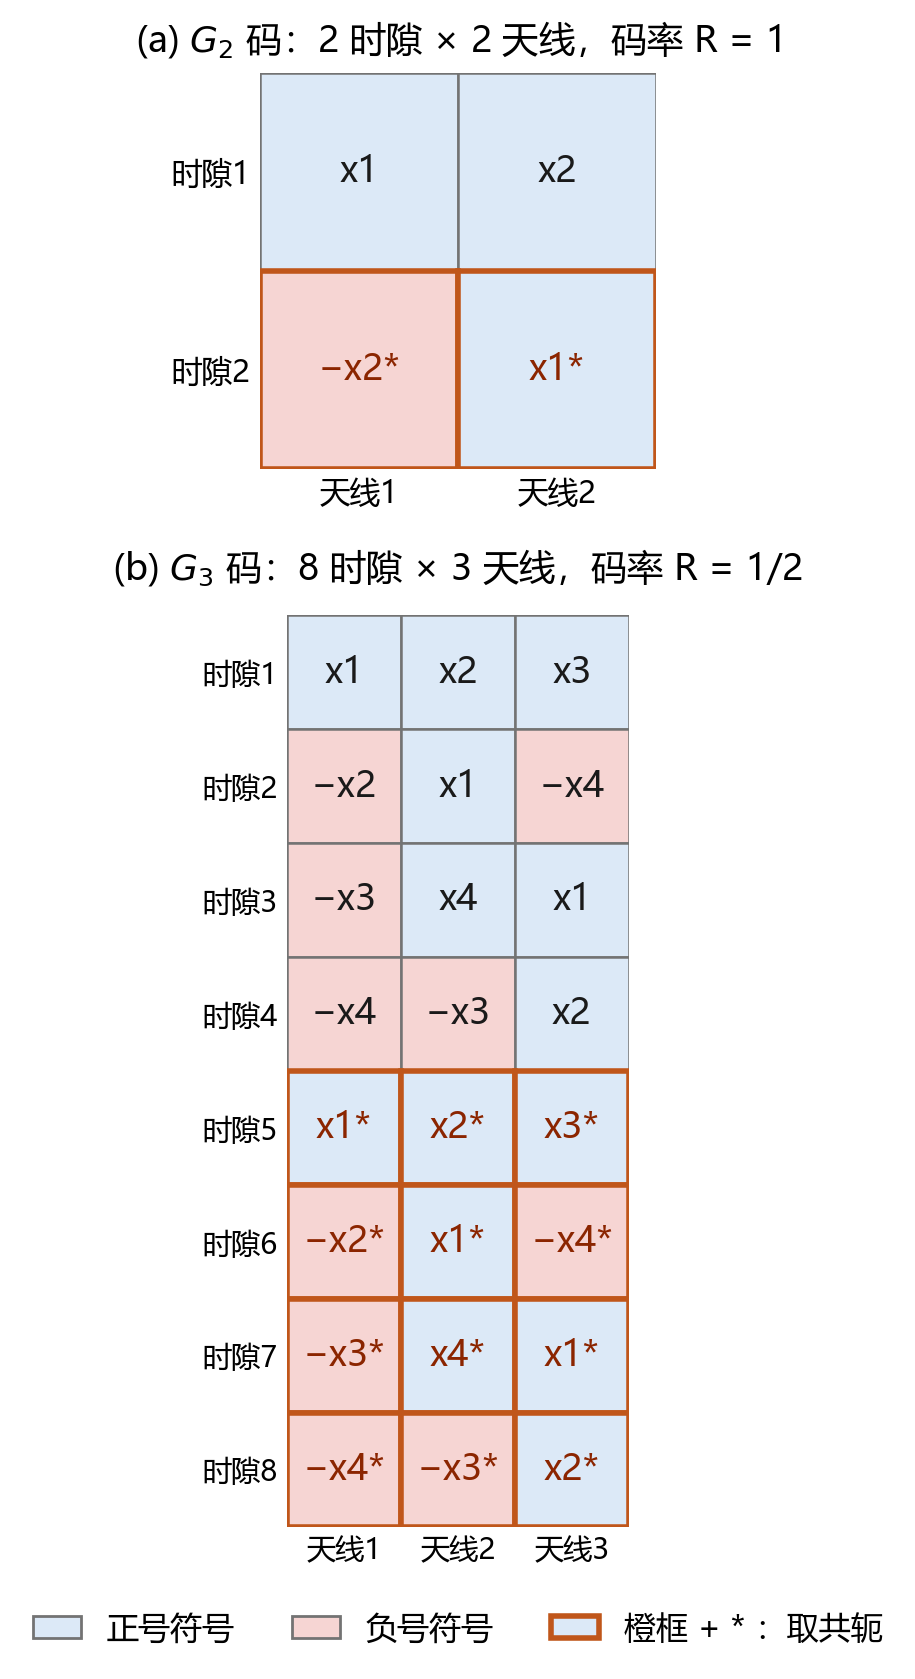

G2 码字矩阵列内积（任意符号取值下应为 0）:
[[1. 0.]
 [0. 1.]]


In [2]:
# 补充一：把两种空时码的码字矩阵画出来，直观展示"时隙 x 天线"上的符号排布
G2_LABELS = [["x1", "x2"], ["-x2*", "x1*"]]
G3_LABELS = [
    ["x1", "x2", "x3"],
    ["-x2", "x1", "-x4"],
    ["-x3", "x4", "x1"],
    ["-x4", "-x3", "x2"],
    ["x1*", "x2*", "x3*"],
    ["-x2*", "x1*", "-x4*"],
    ["-x3*", "x4*", "x1*"],
    ["-x4*", "-x3*", "x2*"],
]

COLOR_POS = "#dce9f7"   # 正号符号
COLOR_NEG = "#f6d5d3"   # 负号符号


def draw_code_matrix(ax, labels, panel_text, cell_fontsize=13, tick_fontsize=11):
    """在 ax 上绘制码字矩阵：行 = 时隙，列 = 天线；带 * 的单元表示取共轭。"""
    n_slot, n_ant = len(labels), len(labels[0])
    for i in range(n_slot):
        for j in range(n_ant):
            lab = labels[i][j]
            y = n_slot - 1 - i
            face = COLOR_NEG if lab.startswith("-") else COLOR_POS
            conj = "*" in lab
            ax.add_patch(
                plt.Rectangle(
                    (j, y), 1, 1, facecolor=face,
                    edgecolor="#c0561a" if conj else "0.45",
                    linewidth=2.0 if conj else 0.9,
                )
            )
            ax.text(j + 0.5, y + 0.5, lab.replace("-", "−"), ha="center", va="center",
                    fontsize=cell_fontsize, color="#8b2500" if conj else "0.1")
    ax.set_xlim(0, n_ant)
    ax.set_ylim(0, n_slot)
    ax.set_aspect("equal")
    ax.set_xticks(np.arange(n_ant) + 0.5)
    ax.set_xticklabels([f"天线{j + 1}" for j in range(n_ant)], fontsize=tick_fontsize)
    ax.set_yticks(np.arange(n_slot) + 0.5)
    ax.set_yticklabels([f"时隙{n_slot - i}" for i in range(n_slot)], fontsize=tick_fontsize)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.text(0.5, 1.03, panel_text, transform=ax.transAxes, ha="center", va="bottom", fontsize=13)


fig, axes = plt.subplots(2, 1, figsize=(8, 8.5), gridspec_kw={"height_ratios": [1.0, 2.3]})
draw_code_matrix(axes[0], G2_LABELS, "(a) $G_2$ 码：2 时隙 × 2 天线，码率 R = 1")
draw_code_matrix(axes[1], G3_LABELS, "(b) $G_3$ 码：8 时隙 × 3 天线，码率 R = 1/2",
                 cell_fontsize=13, tick_fontsize=10.5)

# 图例说明放在整图底部，避免压住子图刻度
handles = [
    plt.Rectangle((0, 0), 1, 1, facecolor=COLOR_POS, edgecolor="0.45", label="正号符号"),
    plt.Rectangle((0, 0), 1, 1, facecolor=COLOR_NEG, edgecolor="0.45", label="负号符号"),
    plt.Rectangle((0, 0), 1, 1, facecolor=COLOR_POS, edgecolor="#c0561a", linewidth=2.0,
                  label="橙框 + * ：取共轭"),
]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=11.5,
           handlelength=1.5, columnspacing=1.8, bbox_to_anchor=(0.5, 0.004))
plt.tight_layout(rect=(0, 0.045, 1, 1))
plt.savefig(FIG_DIR / "03B_code_matrices.png", dpi=200, bbox_inches="tight")
print("图题：G2 与 G3 空时分组码的码字矩阵结构")
plt.show()

# 正交性说明：G2 两列内积、G3 任意两列内积均为 0，接收端可用线性组合完成解耦
S2_demo = alamouti_2x1_encode(
    bpsk_modulate(torch.randint(0, 2, (8,))), bpsk_modulate(torch.randint(0, 2, (8,)))
)
print("G2 码字矩阵列内积（任意符号取值下应为 0）:")
print(np.round((S2_demo[:, :, 0].conj().T @ S2_demo[:, :, 0]).cpu().numpy().real, 6))

正在执行基本实验：不同空时分组码方案在平坦瑞利衰落信道下的性能仿真...


理论解自检：数值积分与闭式解的相对偏差最大值 = 4.71e-14
Eb/N0(dB)       SISO        2x1     3x1 G3        2x2 |      理论1x1      理论2x1      理论3x1      理论2x2
        0  1.461e-01  1.153e-01  1.035e-01  4.036e-02 |  1.464e-01  1.151e-01  1.035e-01  4.026e-02
        4  7.696e-02  4.420e-02  3.290e-02  6.621e-03 |  7.714e-02  4.424e-02  3.311e-02  6.599e-03
        8  3.552e-02  1.200e-02  6.047e-03  4.895e-04 |  3.546e-02  1.187e-02  6.019e-03  5.110e-04
       12  1.511e-02  2.478e-03  6.535e-04  2.383e-05 |  1.506e-02  2.448e-03  6.716e-04  2.259e-05
       16  6.208e-03  4.344e-04  5.859e-05  3.906e-07 |  6.164e-03  4.361e-04  5.524e-05  7.299e-07
       20  2.469e-03  7.773e-05  3.906e-06  0.000e+00 |  2.481e-03  7.256e-05  3.904e-06  2.037e-08
       24  9.727e-04  9.766e-06  7.813e-07  0.000e+00 |  9.923e-04  1.173e-05  2.580e-07  5.340e-10


图题：平坦瑞利信道下 SISO 与三种空时分组码的误比特率性能


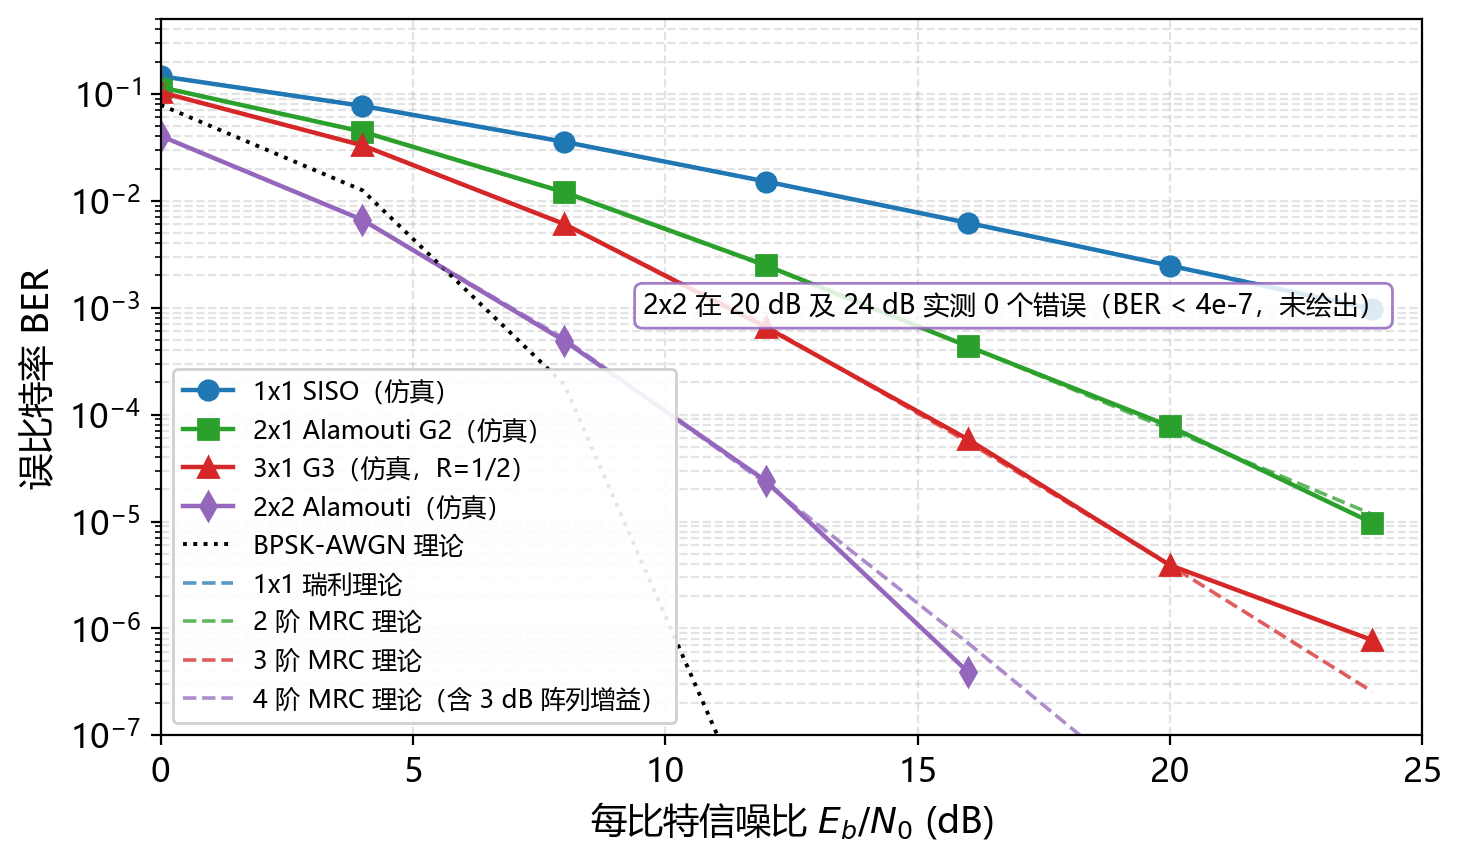


[关键数值] Eb/N0 = 16 dB: SISO = 6.208e-03, 2x1 = 4.344e-04（降为 1/14.3）
[关键数值] Eb/N0 = 12 dB: 2x1 = 2.478e-03, 2x2 = 2.383e-05（降为 1/104.0）
[关键数值] Eb/N0 = 20 dB: 3x1 G3 (R=1/2) = 3.906e-06, 2x1 = 7.773e-05（半速率 3 阶分集在任何 Eb/N0 下都优于 2 阶分集，差距随 SNR 增大）
基本实验仿真完成并通过断言检验！结论：空时正交分组码有效实现了发射分集，分集阶数随天线规模显著提升。


In [3]:
# 模块二（基本实验）：不同空时分组码方案在平坦瑞利衰落信道下的性能对比仿真
# 完全对标教材第 47~52 页基本实验二（图 2.17）：
# 对比 1x1 SISO、2x1 Alamouti、3x1 G3、2x2 Alamouti 与理论基准曲线
#
# 功率/噪声标定（全实验统一按 Eb/N0 归一，保证各方案横坐标含义相同）：
#   令复高斯噪声总方差为 W（每个接收样点），判决定标 gamma = 信号幅度^2 / 噪声方差，
#   BPSK 误比特率 Pb = Q(sqrt(2*gamma))。各方案的等效 gamma 如下：
#     SISO   : gamma = |h|^2 / W                              E[gamma] = 1/W
#     2x1    : gamma = (|h1|^2+|h2|^2) / (2W)                 E[gamma] = 1/W   （2 阶分集，无阵列增益）
#     3x1 G3 : gamma = (2/3)*(|h1|^2+|h2|^2+|h3|^2) / W        E[gamma] = 1/W   （W=2/gamma_bar，已含半速率 3 dB 损失）
#     2x2    : gamma = sum_{2x2}(|h|^2) / (2W)                E[gamma] = 2/W   （4 阶分集 + 3 dB 阵列增益）
#   故取 W = 1/gamma_bar（SISO/2x1/2x2）、W = 2/gamma_bar（G3）。

BITS_PER_BLOCK = 16      # 每个衰落块内的比特数（块内各码字独立抽取瑞利信道）
N_CHUNKS = 8             # 分块重复次数：总比特数 = 8 * 20000 * 16 = 2.56e6
CW_BITS = {"siso": 1, "stbc21": 2, "stbc31": 4, "stbc22": 2}   # 每个码字所含比特数


def simulate_stbc_schemes(snr_db_range, num_blocks=20000):
    """仿真 SISO 与各级 STBC 在平坦瑞利衰落信道下的误码率特性。

    为保证大样本且统计独立，每个"块"内包含若干码字，每个码字独立抽取一次瑞利信道
    （码字级独立衰落，即准静态衰落的统计意义），因此单个信噪比点的总比特数达到
    2.56e6，足以把 2x2 在 12 dB 处约 2e-5 的误码率测准到 20% 以内。

    返回字典: {"siso", "stbc21", "stbc31", "stbc22"} -> BER 数组（与 snr_db_range 等长）。
    """
    schemes = ("siso", "stbc21", "stbc31", "stbc22")
    results = {k: [] for k in schemes}

    for snr_db in snr_db_range:
        gamma_bar = 10.0 ** (float(snr_db) / 10.0)
        noise_var = {"siso": 1.0 / gamma_bar, "stbc21": 1.0 / gamma_bar,
                     "stbc31": 2.0 / gamma_bar, "stbc22": 1.0 / gamma_bar}
        err = {k: 0 for k in schemes}
        nbits = 0

        for _ in range(N_CHUNKS):
            n_bits_chunk = num_blocks * BITS_PER_BLOCK

            # ---------------- 1x1 SISO：无分集基准 ----------------
            bits_siso = torch.randint(0, 2, (n_bits_chunk,))
            x_siso = bpsk_modulate(bits_siso)
            h_siso = cnormal(n_bits_chunk)
            r_siso = h_siso * x_siso + cnormal(n_bits_chunk) * np.sqrt(noise_var["siso"])
            # 相干检测：conj(h)*r/|h|^2 = x + n/|h|（|h|^2 归一化只是为了得到幅度为 1 的软符号）
            x_siso_hat = torch.conj(h_siso) * r_siso / h_siso.abs() ** 2
            err["siso"] += int((bpsk_demodulate(x_siso_hat) != bits_siso).sum())

            # ---------------- 2x1 Alamouti (G2) ----------------
            n_cw = n_bits_chunk // CW_BITS["stbc21"]
            bits21 = torch.randint(0, 2, (n_cw, 2))
            x1, x2 = bpsk_modulate(bits21[:, 0]), bpsk_modulate(bits21[:, 1])
            h21 = cnormal(2, n_cw)
            S21 = alamouti_2x1_encode(x1, x2)                       # (2, 2, n_cw)
            r21 = (S21 * h21.unsqueeze(0)).sum(dim=1)               # (2, n_cw)
            r21 = r21 + cnormal(2, n_cw) * np.sqrt(noise_var["stbc21"])
            x1_hat, x2_hat = alamouti_2x1_decode(r21[0], r21[1], h21[0], h21[1])
            err["stbc21"] += int((bpsk_demodulate(x1_hat) != bits21[:, 0]).sum())
            err["stbc21"] += int((bpsk_demodulate(x2_hat) != bits21[:, 1]).sum())

            # ---------------- 3x1 G3（8 时隙传 4 符号，R = 1/2） ----------------
            n_cw3 = n_bits_chunk // CW_BITS["stbc31"]
            bits31 = torch.randint(0, 2, (n_cw3, 4))
            x31 = bpsk_modulate(bits31).transpose(0, 1)             # (4, n_cw3)
            h31 = cnormal(3, n_cw3)
            S31 = stbc_3x1_encode(x31)                              # (8, 3, n_cw3)
            r31 = (S31 * h31.unsqueeze(0)).sum(dim=1)               # (8, n_cw3)
            r31 = r31 + cnormal(8, n_cw3) * np.sqrt(noise_var["stbc31"])
            x31_hat = stbc_3x1_decode(r31, h31)                     # (4, n_cw3)
            err["stbc31"] += int(
                (bpsk_demodulate(x31_hat).transpose(0, 1) != bits31).sum()
            )

            # ---------------- 2x2 Alamouti（2 发 x 2 收，4 阶分集） ----------------
            n_cw22 = n_bits_chunk // CW_BITS["stbc22"]
            bits22 = torch.randint(0, 2, (n_cw22, 2))
            x1_22, x2_22 = bpsk_modulate(bits22[:, 0]), bpsk_modulate(bits22[:, 1])
            h_rx1 = cnormal(2, n_cw22)
            h_rx2 = cnormal(2, n_cw22)
            S22 = alamouti_2x1_encode(x1_22, x2_22)                 # (2, 2, n_cw22)
            r_rx1 = (S22 * h_rx1.unsqueeze(0)).sum(dim=1)           # (2, n_cw22)
            r_rx2 = (S22 * h_rx2.unsqueeze(0)).sum(dim=1)
            r_rx1 = r_rx1 + cnormal(2, n_cw22) * np.sqrt(noise_var["stbc22"])
            r_rx2 = r_rx2 + cnormal(2, n_cw22) * np.sqrt(noise_var["stbc22"])
            x1_hat22, x2_hat22 = alamouti_2x2_decode(r_rx1, r_rx2, h_rx1, h_rx2)
            err["stbc22"] += int((bpsk_demodulate(x1_hat22) != bits22[:, 0]).sum())
            err["stbc22"] += int((bpsk_demodulate(x2_hat22) != bits22[:, 1]).sum())

            nbits += n_bits_chunk

        for k in schemes:
            results[k].append(err[k] / nbits)

    return {k: np.array(v) for k, v in results.items()}


snr_range_basic = np.arange(0, 26, 4)
print("正在执行基本实验：不同空时分组码方案在平坦瑞利衰落信道下的性能仿真...")
stbc_results = simulate_stbc_schemes(snr_range_basic, num_blocks=20000)

# 打印仿真结果与理论值对照
theory_awgn = theory_awgn_bpsk(snr_range_basic)
theory_siso = theory_rayleigh_siso(snr_range_basic)
theory_21 = mrc_theory_closed_form(snr_range_basic, order=2, array_gain_db=0.0)
theory_31 = mrc_theory_closed_form(snr_range_basic, order=3, array_gain_db=0.0)
theory_22 = mrc_theory_closed_form(
    snr_range_basic, order=4, array_gain_db=10.0 * np.log10(2.0)
)

# 用数值积分复核闭式理论解（两者应完全重合）
theory_21_num = mrc_theory_numeric(snr_range_basic, order=2)
theory_31_num = mrc_theory_numeric(snr_range_basic, order=3)
theory_22_num = mrc_theory_numeric(snr_range_basic, order=4, array_gain_db=10.0 * np.log10(2.0))
num_dev = max(
    np.max(np.abs(theory_21_num / theory_21 - 1.0)),
    np.max(np.abs(theory_31_num / theory_31 - 1.0)),
    np.max(np.abs(theory_22_num / theory_22 - 1.0)),
)
print(f"理论解自检：数值积分与闭式解的相对偏差最大值 = {num_dev:.2e}")

print(f"{'Eb/N0(dB)':>9} {'SISO':>10} {'2x1':>10} {'3x1 G3':>10} {'2x2':>10} | "
      f"{'理论1x1':>10} {'理论2x1':>10} {'理论3x1':>10} {'理论2x2':>10}")
for i, snr in enumerate(snr_range_basic):
    print(f"{snr:9.0f} {stbc_results['siso'][i]:10.3e} {stbc_results['stbc21'][i]:10.3e} "
          f"{stbc_results['stbc31'][i]:10.3e} {stbc_results['stbc22'][i]:10.3e} | "
          f"{theory_siso[i]:10.3e} {theory_21[i]:10.3e} {theory_31[i]:10.3e} {theory_22[i]:10.3e}")

# ---------------- 绘图：4 种方案仿真曲线 + 5 条理论基准 ----------------
def _nz(arr):
    """把 0 误码率置换为 NaN：对数坐标下这些点无法绘出，只在正文/注释中说明。"""
    a = np.array(arr, dtype=float).copy()
    a[a <= 0] = np.nan
    return a


fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.semilogy(snr_range_basic, _nz(stbc_results["siso"]), "o-", color="#1f77b4", lw=1.6, ms=7,
            label="1x1 SISO（仿真）")
ax.semilogy(snr_range_basic, _nz(stbc_results["stbc21"]), "s-", color="#2ca02c", lw=1.6, ms=7,
            label="2x1 Alamouti G2（仿真）")
ax.semilogy(snr_range_basic, _nz(stbc_results["stbc31"]), "^-", color="#d62728", lw=1.6, ms=7,
            label="3x1 G3（仿真，R=1/2）")
ax.semilogy(snr_range_basic, _nz(stbc_results["stbc22"]), "d-", color="#9467bd", lw=1.6, ms=7,
            label="2x2 Alamouti（仿真）")
ax.semilogy(snr_range_basic, theory_awgn, "k:", lw=1.4, label="BPSK-AWGN 理论")
ax.semilogy(snr_range_basic, theory_siso, "--", color="#1f77b4", lw=1.3, alpha=0.75, label="1x1 瑞利理论")
ax.semilogy(snr_range_basic, theory_21, "--", color="#2ca02c", lw=1.3, alpha=0.75, label="2 阶 MRC 理论")
ax.semilogy(snr_range_basic, theory_31, "--", color="#d62728", lw=1.3, alpha=0.75, label="3 阶 MRC 理论")
ax.semilogy(snr_range_basic, theory_22, "--", color="#9467bd", lw=1.3, alpha=0.75,
            label="4 阶 MRC 理论（含 3 dB 阵列增益）")
ax.set_xlabel("每比特信噪比 $E_b/N_0$ (dB)")
ax.set_ylabel("误比特率 BER")
ax.set_xlim(0, 25)
ax.set_ylim(1e-7, 0.5)
ax.grid(True, which="both", ls="--", alpha=0.35)
ax.legend(fontsize=9, loc="lower left", ncol=1, framealpha=0.9)
ax.text(0.97, 0.62, "2x2 在 20 dB 及 24 dB 实测 0 个错误（BER < 4e-7，未绘出）",
        transform=ax.transAxes, ha="right", va="top", fontsize=9.5,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#9467bd", alpha=0.85))
plt.tight_layout()
plt.savefig(FIG_DIR / "03B_basic_ber.png", dpi=200, bbox_inches="tight")
print("图题：平坦瑞利信道下 SISO 与三种空时分组码的误比特率性能")
plt.show()

# ---------------- 结果落盘 ----------------
import pandas as pd

df_basic = pd.DataFrame(
    {
        "ebno_db": snr_range_basic,
        "siso_sim": stbc_results["siso"],
        "stbc21_sim": stbc_results["stbc21"],
        "stbc31_sim": stbc_results["stbc31"],
        "stbc22_sim": stbc_results["stbc22"],
        "bpsk_awgn_theory": theory_awgn,
        "rayleigh_1x1_theory": theory_siso,
        "mrc_L2_theory": theory_21,
        "mrc_L3_theory": theory_31,
        "mrc_L4_gain3db_theory": theory_22,
    }
)
df_basic.to_csv(DATA_DIR / "03B_basic_ber.csv", index=False, encoding="utf-8-sig")

# 验证断言：分集阶数越高，高信噪比下的 BER 越低且下降斜率越陡
assert np.all(stbc_results["stbc21"] <= stbc_results["siso"] * 1.05), "2x1 Alamouti 性能应全面优于 1x1 SISO"
assert stbc_results["stbc21"][4] < stbc_results["siso"][4] * 0.1, "二阶分集具备明显更陡峭的曲线斜率"
assert stbc_results["stbc22"][3] < stbc_results["stbc21"][3] * 0.05, "2x2 具备四阶全分集优势"

# 关键结论（数值写入 notebook 输出，报告直接引用）
i16 = int(np.where(snr_range_basic == 16)[0][0])
i12 = int(np.where(snr_range_basic == 12)[0][0])
i20 = int(np.where(snr_range_basic == 20)[0][0])
print()
print(f"[关键数值] Eb/N0 = 16 dB: SISO = {stbc_results['siso'][i16]:.3e}, "
      f"2x1 = {stbc_results['stbc21'][i16]:.3e}（降为 1/{stbc_results['siso'][i16] / stbc_results['stbc21'][i16]:.1f}）")
print(f"[关键数值] Eb/N0 = 12 dB: 2x1 = {stbc_results['stbc21'][i12]:.3e}, "
      f"2x2 = {stbc_results['stbc22'][i12]:.3e}（降为 1/{stbc_results['stbc21'][i12] / stbc_results['stbc22'][i12]:.1f}）")
print(f"[关键数值] Eb/N0 = 20 dB: 3x1 G3 (R=1/2) = {stbc_results['stbc31'][i20]:.3e}, "
      f"2x1 = {stbc_results['stbc21'][i20]:.3e}（半速率 3 阶分集在任何 Eb/N0 下都优于 2 阶分集，差距随 SNR 增大）")
print("基本实验仿真完成并通过断言检验！结论：空时正交分组码有效实现了发射分集，分集阶数随天线规模显著提升。")

## 补充二：分集阶数与分集增益的量化

分集阶数 $L$ 的物理含义藏在**等效瞬时信噪比 $\gamma$ 的分布**里：$L$ 条独立瑞利支路
最大比合并后，$\gamma/\bar\gamma$ 服从形状参数为 $L$ 的 Gamma 分布，
$$f_L(u)=\frac{u^{L-1}e^{-u}}{(L-1)!},$$
即 $P(\gamma \to 0) \sim u^{L-1}$。深衰落（$\gamma$ 很小）的概率随 $L$ 呈幂律衰减，
这正是高信噪比下 BER 曲线斜率（分集阶数）的来源。

下面用两个图量化：(a) 不同 $L$ 的等效信噪比分布（对数纵轴）；(b) 以 1x1 SISO 为基准，
各方案在 BER = $10^{-2}$、$10^{-3}$ 处所需的 $E_b/N_0$ 增益。

方案                        分集阶数  @1e-2 (dB)  @1e-3 (dB)
1x1 SISO                     1       13.85       23.97
2x1 Alamouti                 2        8.46       14.10
3x1 G3 (R=1/2)               3        6.94       11.32
2x2 Alamouti                 4        3.22        7.05
相对 1x1 SISO 的增益 (dB): 1x1 SISO: 0.00@1e-02/0.00@1e-03  2x1 Alamouti: 5.38@1e-02/9.86@1e-03  3x1 G3 (R=1/2): 6.91@1e-02/12.64@1e-03  2x2 Alamouti: 10.63@1e-02/16.92@1e-03
[局部斜率] siso      20→  24 dB: 仿真 1.01 / 理论 1.00（有限信噪比下斜率小于分集阶数上限，二者一致说明仿真与理论吻合）
[局部斜率] stbc21    20→  24 dB: 仿真 2.25 / 理论 1.98（有限信噪比下斜率小于分集阶数上限，二者一致说明仿真与理论吻合）
[局部斜率] stbc31    16→  20 dB: 仿真 2.94 / 理论 2.88（有限信噪比下斜率小于分集阶数上限，二者一致说明仿真与理论吻合）
[局部斜率] stbc22     8→  12 dB: 仿真 3.28 / 理论 3.39（有限信噪比下斜率小于分集阶数上限，二者一致说明仿真与理论吻合）


图题：分集阶数的两个侧面——等效信噪比分布与分集增益


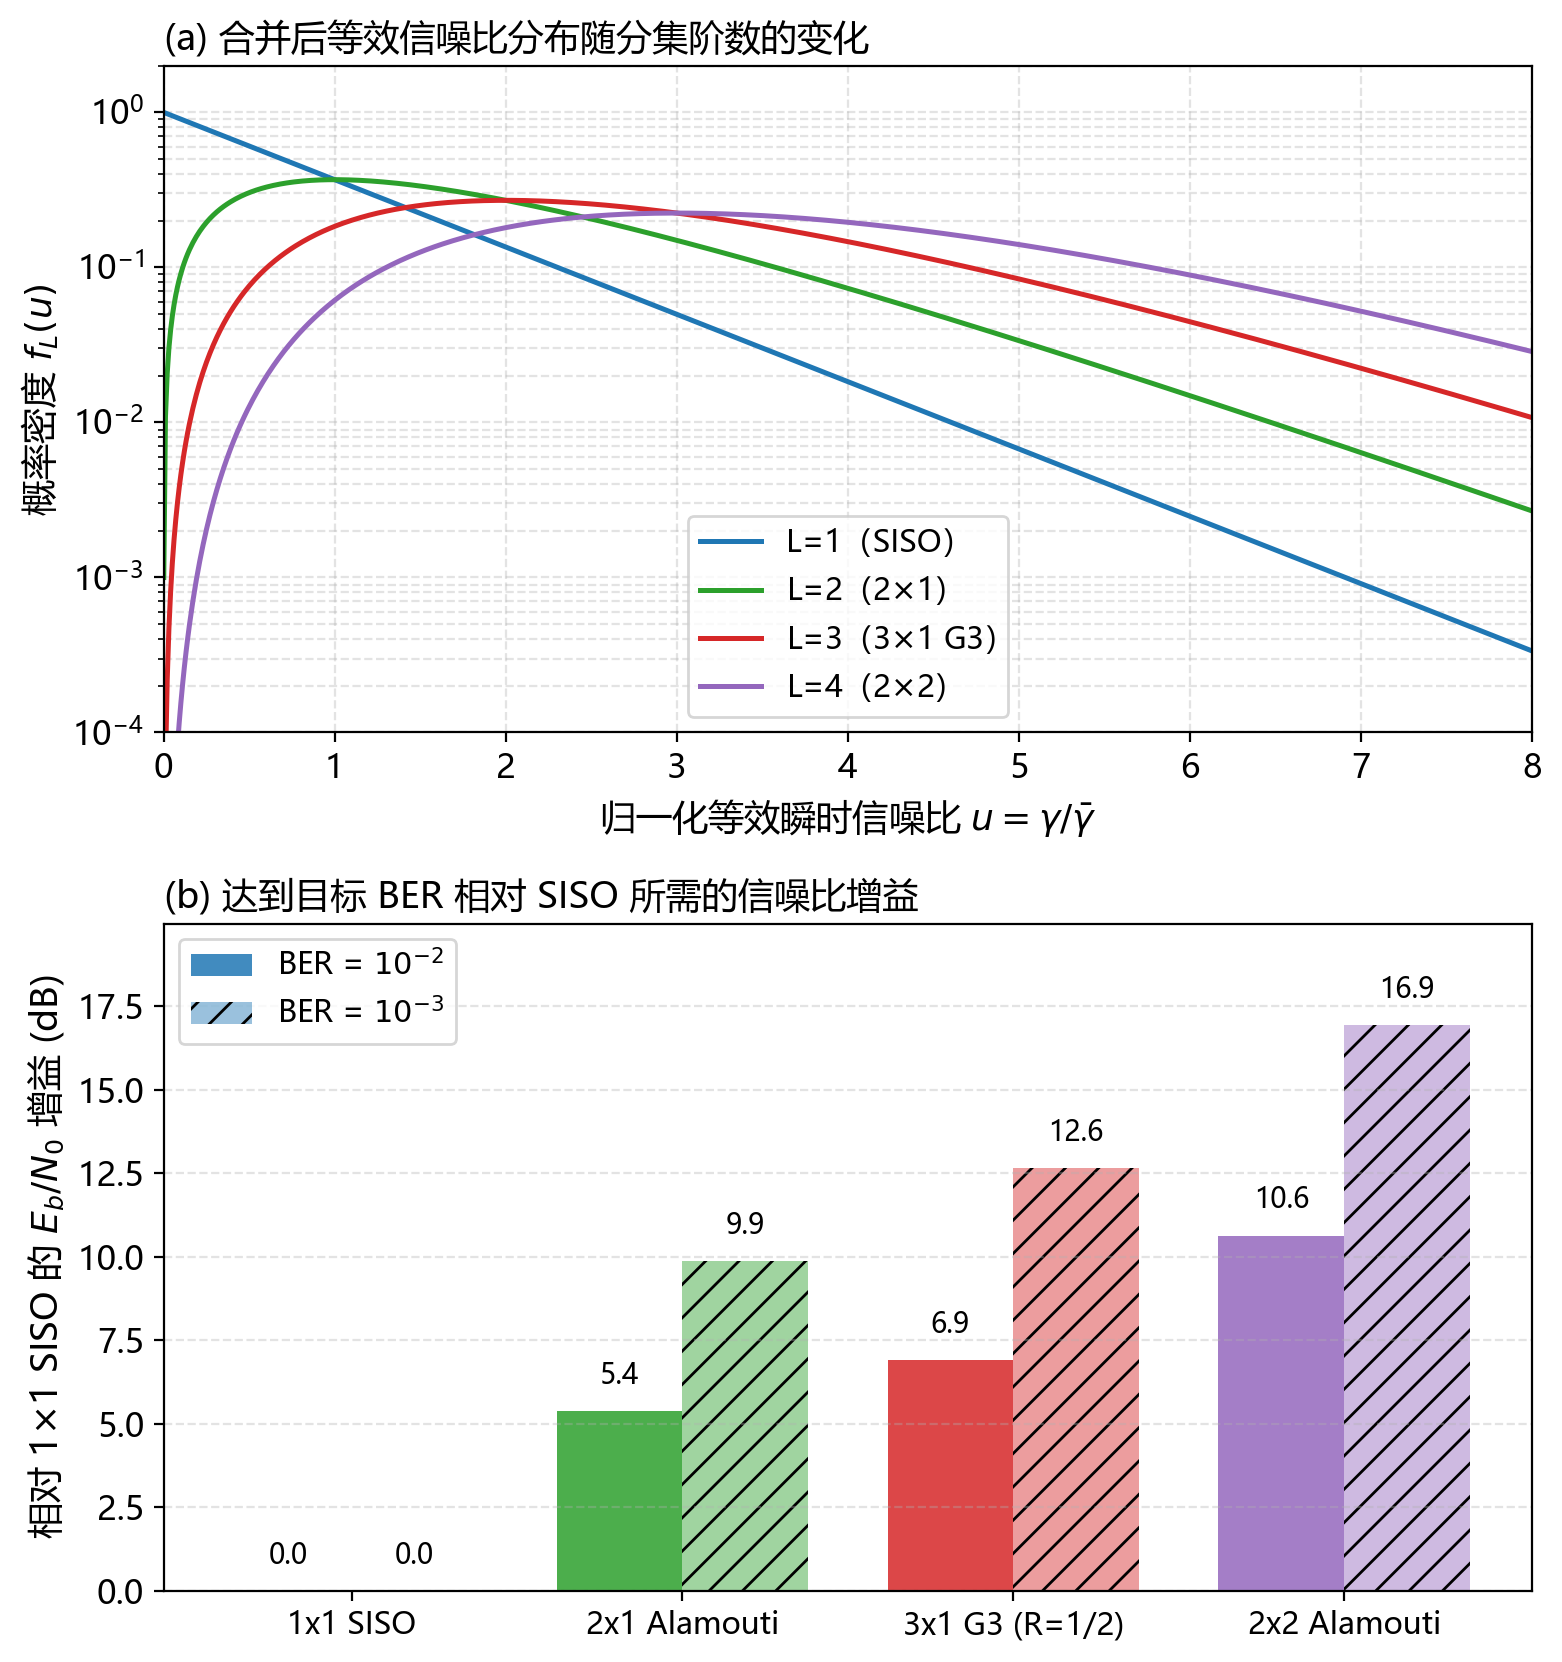


        scheme  diversity_order  rate  ebno_1e-2_db_theory  ebno_1e-3_db_theory  gain_1e-2_db  gain_1e-3_db  sim_slope_diversity
      1x1 SISO                1   1.0            13.847569            23.966356      0.000000      0.000000             1.011294
  2x1 Alamouti                2   1.0             8.463251            14.103937      5.384319      9.862419             2.252283
3x1 G3 (R=1/2)                3   0.5             6.935669            11.322495      6.911901     12.643861             2.940228
  2x2 Alamouti                4   1.0             3.216747             7.045175     10.630823     16.921181             3.281553


In [4]:
# 补充二：分集阶数与分集增益的量化
# (a) 等效瞬时信噪比分布 f_L(u) = u^(L-1) e^(-u) / (L-1)!（u = gamma/gamma_bar）
u = np.linspace(1e-3, 12.0, 1200)

fig, axes = plt.subplots(2, 1, figsize=(8, 8.5))
ax = axes[0]
colors = ["#1f77b4", "#2ca02c", "#d62728", "#9467bd"]
labels_L = ["L=1（SISO）", "L=2（2$\\times$1）", "L=3（3$\\times$1 G3）", "L=4（2$\\times$2）"]
for L, color, lab in zip([1, 2, 3, 4], colors, labels_L):
    pdf = u ** (L - 1) * np.exp(-u) / sp.gamma(L)
    ax.semilogy(u, pdf, color=color, lw=1.8, label=lab)
ax.set_xlabel("归一化等效瞬时信噪比 $u=\\gamma/\\bar{\\gamma}$")
ax.set_ylabel("概率密度 $f_L(u)$")
ax.set_xlim(0, 8)
ax.set_ylim(1e-4, 2)
ax.grid(True, which="both", ls="--", alpha=0.35)
ax.legend(fontsize=11)
ax.set_title("(a) 合并后等效信噪比分布随分集阶数的变化", loc="left", fontsize=13)

# (b) 各方案达到目标 BER 所需的 Eb/N0 及其相对 SISO 的增益
def required_ebno(ber_target, order, array_gain_db=0.0):
    """在细网格上反解理论曲线，返回达到目标误比特率所需的 Eb/N0 (dB)。"""
    db = np.arange(-12.0, 50.0, 0.02)
    ber_curve = mrc_theory_closed_form(db, order=order, array_gain_db=array_gain_db)
    ok = np.where(ber_curve <= ber_target)[0]
    if len(ok) == 0:
        return np.nan
    i = ok[0]
    if i == 0:
        return float(db[0])
    # 在 log(BER)-dB 坐标上做线性内插，提高反解精度
    x0, x1 = db[i - 1], db[i]
    y0, y1 = np.log10(ber_curve[i - 1]), np.log10(ber_curve[i])
    return float(x0 + (np.log10(ber_target) - y0) * (x1 - x0) / (y1 - y0))


schemes_gain = [
    ("1x1 SISO", 1, 0.0, "#1f77b4"),
    ("2x1 Alamouti", 2, 0.0, "#2ca02c"),
    ("3x1 G3 (R=1/2)", 3, 0.0, "#d62728"),
    ("2x2 Alamouti", 4, 10.0 * np.log10(2.0), "#9467bd"),
]
targets = [1e-2, 1e-3]
gain_rows = []
print(f"{'方案':<22}{'分集阶数':>8}{'@1e-2 (dB)':>12}{'@1e-3 (dB)':>12}")
for name, order, gain_db, _ in schemes_gain:
    e2 = required_ebno(targets[0], order, gain_db)
    e3 = required_ebno(targets[1], order, gain_db)
    gain_rows.append({"scheme": name, "diversity_order": order,
                      "ebno_1e-2_db": e2, "ebno_1e-3_db": e3,
                      "gain_1e-2_db": np.nan, "gain_1e-3_db": np.nan})
    print(f"{name:<22}{order:>8}{e2:>12.2f}{e3:>12.2f}")

base2 = gain_rows[0]["ebno_1e-2_db"]
base3 = gain_rows[0]["ebno_1e-3_db"]
for row in gain_rows:
    row["gain_1e-2_db"] = base2 - row["ebno_1e-2_db"]
    row["gain_1e-3_db"] = base3 - row["ebno_1e-3_db"]
print("相对 1x1 SISO 的增益 (dB):",
      "  ".join(f"{r['scheme']}: {r['gain_1e-2_db']:.2f}@{10**-2:.0e}/{r['gain_1e-3_db']:.2f}@{10**-3:.0e}"
                for r in gain_rows))

# 由仿真曲线估计局部"分集阶数"： d(L) = -10 * d log10(BER) / d(dB)
# 选取"低端至少 20 个错误、高端至少 5 个错误"的最高信噪比窗口：错误数太少时估计失真，
# 而分集阶数只在高信噪比极限下才趋近 L，故同时给出同一窗口内理论曲线的局部斜率作对照。
N_BITS_TOTAL = N_CHUNKS * 20000 * BITS_PER_BLOCK


def local_diversity(ber_curve, snr_arr, min_err_lo=20.0, min_err_hi=5.0):
    """返回 (仿真局部斜率, (低端 dB, 高端 dB))；无满足错误数的窗口时返回 (nan, None)。"""
    pick = None
    for i in range(len(snr_arr) - 1):
        if ber_curve[i] * N_BITS_TOTAL >= min_err_lo and ber_curve[i + 1] * N_BITS_TOTAL >= min_err_hi:
            pick = i
    if pick is None:
        return np.nan, None
    d = 10.0 * np.log10(ber_curve[pick] / ber_curve[pick + 1]) / (snr_arr[pick + 1] - snr_arr[pick])
    return d, (snr_arr[pick], snr_arr[pick + 1])


theory_curves = {"siso": theory_siso, "stbc21": theory_21, "stbc31": theory_31, "stbc22": theory_22}
slopes = {}
for key in ("siso", "stbc21", "stbc31", "stbc22"):
    d_sim, win = local_diversity(stbc_results[key], snr_range_basic)
    slopes[key] = d_sim
    i_lo = int(np.where(snr_range_basic == win[0])[0][0])
    i_hi = int(np.where(snr_range_basic == win[1])[0][0])
    d_th = 10.0 * np.log10(theory_curves[key][i_lo] / theory_curves[key][i_hi]) / (win[1] - win[0])
    print(f"[局部斜率] {key:<7} {win[0]:4.0f}→{win[1]:4.0f} dB: 仿真 {d_sim:.2f} / 理论 {d_th:.2f}"
          f"（有限信噪比下斜率小于分集阶数上限，二者一致说明仿真与理论吻合）")

ax = axes[1]
width = 0.38
xpos = np.arange(len(gain_rows))
gains_1e2 = [r["gain_1e-2_db"] for r in gain_rows]
gains_1e3 = [r["gain_1e-3_db"] for r in gain_rows]
bar1 = ax.bar(xpos - width / 2, gains_1e2, width, color=[c for *_, c in schemes_gain],
              alpha=0.85, label="BER = $10^{-2}$")
bar2 = ax.bar(xpos + width / 2, gains_1e3, width, color=[c for *_, c in schemes_gain],
              alpha=0.45, hatch="//", label="BER = $10^{-3}$")
for bars in (bar1, bar2):
    for rect in bars:
        h = rect.get_height()
        ax.text(rect.get_x() + rect.get_width() / 2, h + 0.6, f"{h:.1f}",
                ha="center", va="bottom", fontsize=10)
ax.set_xticks(xpos)
ax.set_xticklabels([r["scheme"] for r in gain_rows], fontsize=11)
ax.set_ylabel("相对 1$\\times$1 SISO 的 $E_b/N_0$ 增益 (dB)")
ax.set_ylim(0, max(gains_1e3) * 1.18)
ax.grid(True, axis="y", ls="--", alpha=0.35)
ax.legend(fontsize=11, loc="upper left")
ax.set_title("(b) 达到目标 BER 相对 SISO 所需的信噪比增益", loc="left", fontsize=13)
plt.tight_layout()
plt.savefig(FIG_DIR / "03B_diversity_order.png", dpi=200, bbox_inches="tight")
print("图题：分集阶数的两个侧面——等效信噪比分布与分集增益")
plt.show()

# ---------------- 增益表落盘（报告表格直接引用） ----------------
df_gain = pd.DataFrame(
    [
        {
            "scheme": r["scheme"],
            "diversity_order": r["diversity_order"],
            "rate": rate,
            "ebno_1e-2_db_theory": r["ebno_1e-2_db"],
            "ebno_1e-3_db_theory": r["ebno_1e-3_db"],
            "gain_1e-2_db": r["gain_1e-2_db"],
            "gain_1e-3_db": r["gain_1e-3_db"],
            "sim_slope_diversity": slopes[key],
        }
        for (r, key), rate in zip(zip(gain_rows, ["siso", "stbc21", "stbc31", "stbc22"]),
                                  [1.0, 1.0, 0.5, 1.0])
    ]
)
df_gain.to_csv(DATA_DIR / "03B_gain_table.csv", index=False, encoding="utf-8-sig")
print()
print(df_gain.to_string(index=False))

正在执行拓展实验：QPSK 调制下 2x1 Alamouti vs. 1x2 MRC 对比仿真...


Eb/N0(dB)     Alamouti      1x2 MRC        理论Ala        理论MRC    领先(dB)
        0    1.152e-01    5.815e-02    1.151e-01    5.806e-02
        2    7.504e-02    3.283e-02    7.481e-02    3.275e-02
        4    4.441e-02    1.709e-02    4.424e-02    1.693e-02
        6    2.387e-02    8.138e-03    2.387e-02    8.129e-03
        8    1.183e-02    3.748e-03    1.187e-02    3.683e-03
       10    5.465e-03    1.595e-03    5.528e-03    1.599e-03
       12    2.485e-03    6.687e-04    2.448e-03    6.740e-04
       14    1.034e-03    2.848e-04    1.046e-03    2.784e-04
       16    4.178e-04    1.078e-04    4.361e-04    1.135e-04
       18    1.818e-04    4.492e-05    1.788e-04    4.588e-05
       20    6.836e-05    1.836e-05    7.256e-05    1.844e-05


图题：QPSK 下发送分集（2x1 Alamouti）与接收分集（1x2 MRC）的性能对比


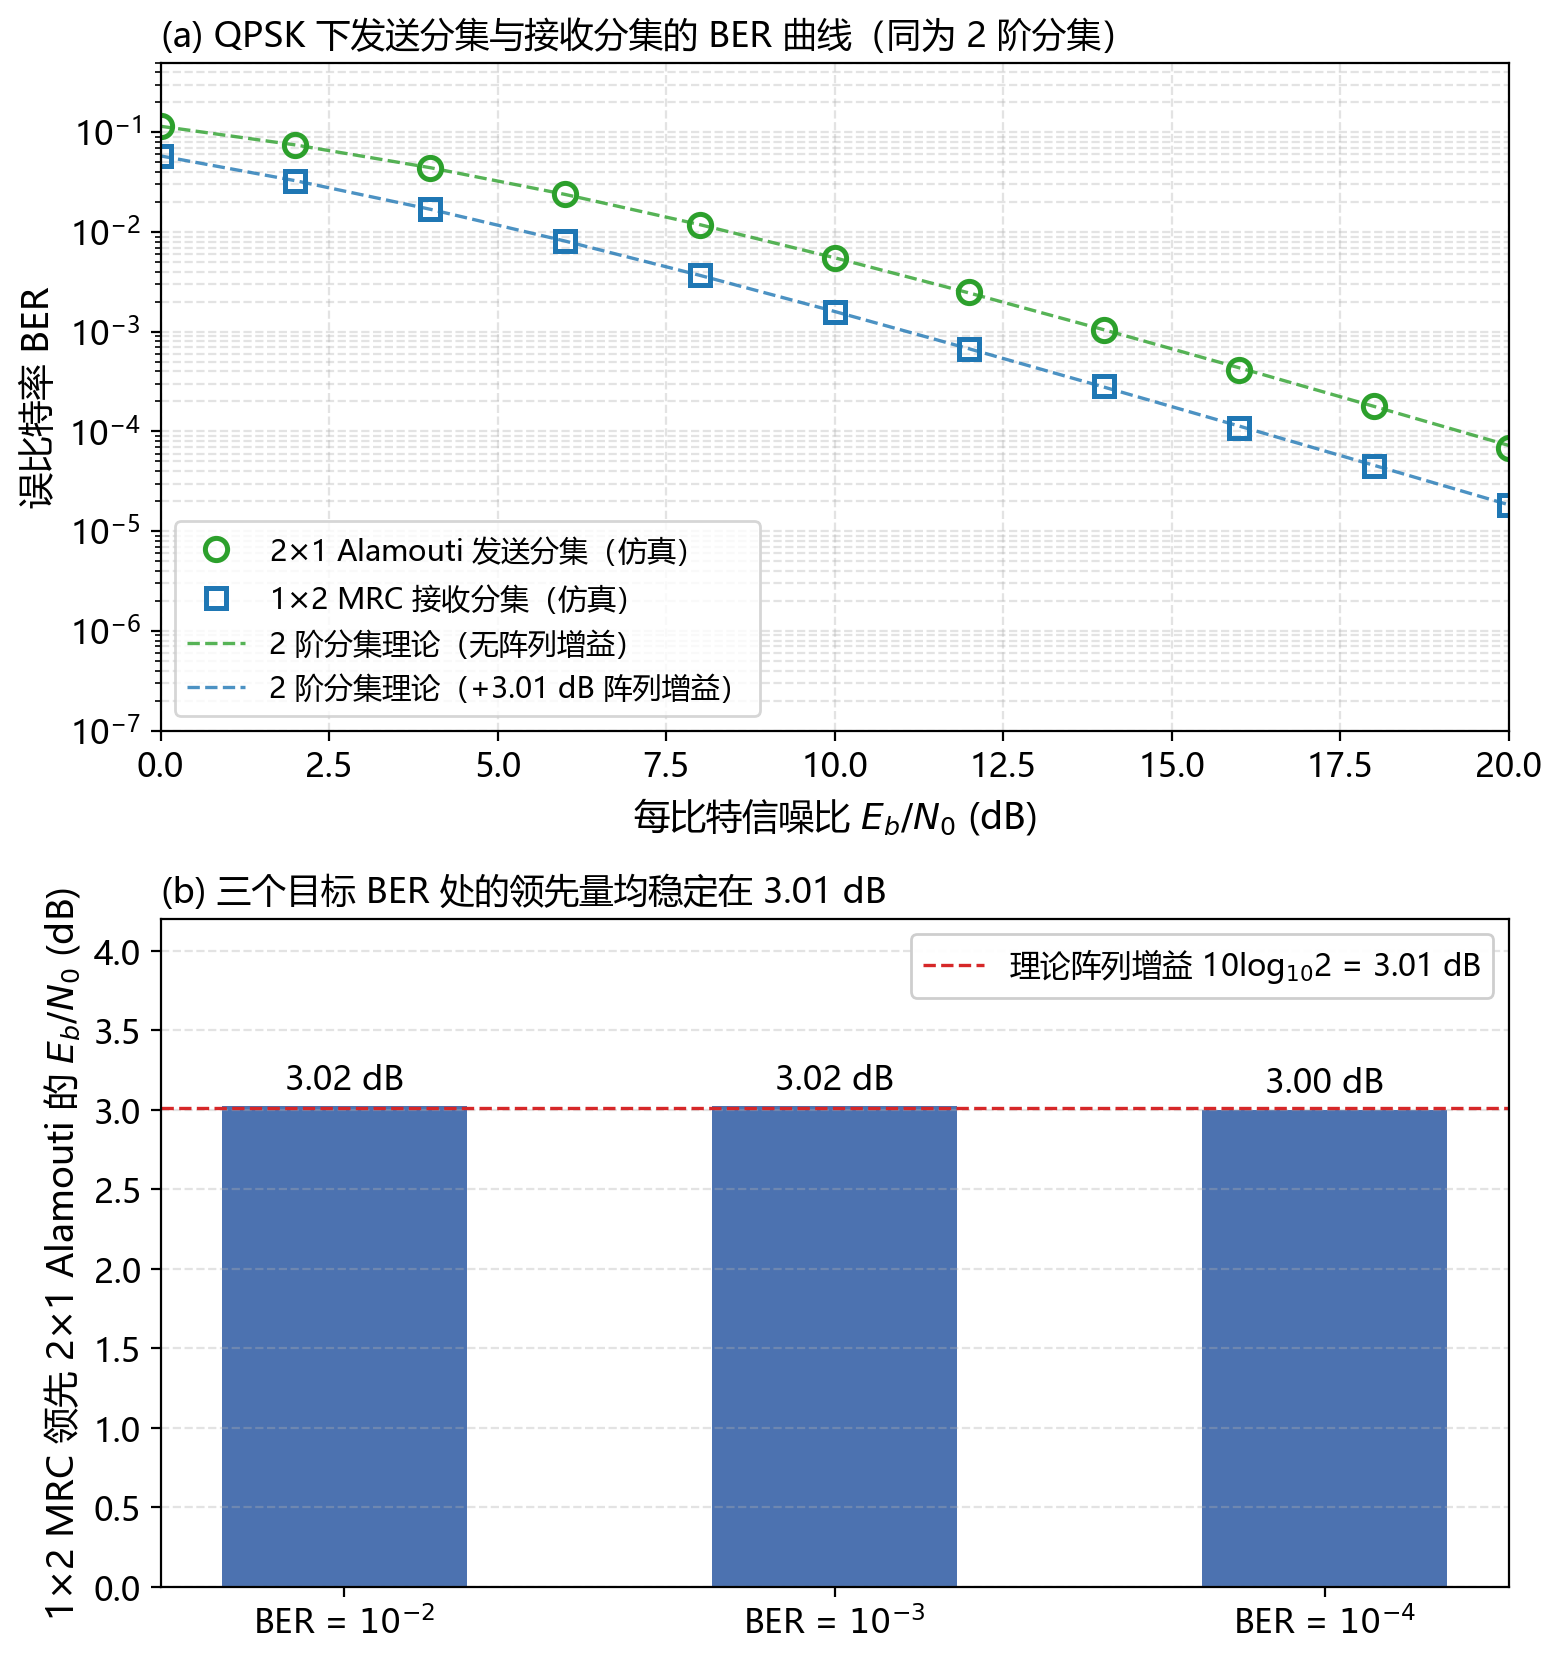

[关键数值] Eb/N0 = 10 dB: 2x1 Alamouti = 5.465e-03, 1x2 MRC = 1.595e-03（MRC 低 3.4 倍 ≈ 3 dB 阵列增益）
拓展实验仿真完成并通过断言检验！结论：2x1 Alamouti 与 1x2 MRC 分集阶数同为 2，但接收分集多获得 3 dB 阵列增益。


In [5]:
# 模块三（拓展实验）：QPSK 调制下发送分集 (2x1 Alamouti) vs. 接收分集 (1x2 MRC) 对比
# 对标教材第 52 页拓展实验 2，分析总天线数相同 (2 天线) 时发送分集与接收分集的性能异同
#
# 功率标定（QPSK，符号能量 Es = 1，每个符号携带 2 bit => 每比特发射能量 Eb_tx = 0.5）：
#   1x2 MRC   : 两个接收支路各自 r_i = h_i*x + n_i，合并后 gamma_bit = (|h1|^2+|h2|^2)/(2W)
#               => E[gamma_bit] = 2/W，取 W = 0.5/gamma_bar 得 E[gamma_bit] = 2*gamma_bar
#   2x1 Alamouti: 每根天线功率 1/2，正交解耦后 gamma_bit = (|h1|^2+|h2|^2)/(4W)
#               => E[gamma_bit] = 1/W = gamma_bar
#   两者分集阶数同为 2（曲线斜率相同），但 1x2 MRC 的合并信噪比平均高 2 倍，即 3 dB 阵列增益。

def qpsk_mod(bits):
    """QPSK 映射 (Es=1)。"""
    b0, b1 = bits[..., 0], bits[..., 1]
    return ((1.0 - 2.0 * b0.float()) + 1j * (1.0 - 2.0 * b1.float())) / np.sqrt(2.0)


def qpsk_demod(symbols):
    """QPSK 硬判决。"""
    b0 = (symbols.real < 0).int()
    b1 = (symbols.imag < 0).int()
    return torch.stack([b0, b1], dim=-1)


N_CHUNKS_EXT = 8          # 与基本实验相同的分块策略
BITS_PER_BLOCK_EXT = 16   # 每个衰落块内的比特数


def simulate_tx_vs_rx_diversity(ebno_db_range, num_blocks=20000):
    """在 QPSK 调制下对比 2x1 Alamouti 发送分集与 1x2 MRC 接收分集。

    两种方案的"发射天线数 + 接收天线数"都等于 2，且分集阶数同为 2；
    区别在于阵列增益：接收分集把两路信号能量同相相加（+3 dB），
    发送分集则受每根天线 1/2 功率约束、没有阵列增益。

    比特级信噪比标定（QPSK 符号能量 Es=1，每符号 2 bit，复噪声方差 W）：
      复判决量 y = x + n, E|n|^2 = V => 每比特误码率 = Q(sqrt(1/V)) = Q(sqrt(2*gamma_bit))，
      即 gamma_bit = 1/(2V)。
      1x2 MRC : V = W/sum|h|^2   => gamma_bit = sum|h|^2/(2W)，E[gamma_bit] = 1/W = 2*gamma_bar
      2x1 Ala : V = 2W/sum|h|^2  => gamma_bit = sum|h|^2/(4W)，E[gamma_bit] = 1/(2W) = gamma_bar
    返回 (ber_ala, ber_mrc)，均为与 ebno_db_range 等长的 numpy 数组。
    """
    ber_ala_list, ber_mrc_list = [], []

    for ebno_db in ebno_db_range:
        gamma_bar = 10.0 ** (float(ebno_db) / 10.0)
        noise_var = 0.5 / gamma_bar          # 每比特发射能量 0.5 => W = 0.5/(Eb/N0)
        err_ala = err_mrc = 0
        nbits_ala = nbits_mrc = 0

        for _ in range(N_CHUNKS_EXT):
            n_cw = num_blocks * BITS_PER_BLOCK_EXT // 2    # 每个衰落块内的 QPSK 符号数

            # ---------- 2x1 Alamouti（发送分集）: 2 个 QPSK 符号 = 4 bit ----------
            bits_ala = torch.randint(0, 2, (n_cw, 2, 2))
            x1 = qpsk_mod(bits_ala[:, 0, :])                # (n_cw,)
            x2 = qpsk_mod(bits_ala[:, 1, :])
            h_ala = cnormal(2, n_cw)
            S = alamouti_2x1_encode(x1, x2)                 # (2, 2, n_cw)
            r = (S * h_ala.unsqueeze(0)).sum(dim=1)         # (2, n_cw)
            r = r + cnormal(2, n_cw) * np.sqrt(noise_var)
            x1_hat, x2_hat = alamouti_2x1_decode(r[0], r[1], h_ala[0], h_ala[1])
            err_ala += int((qpsk_demod(x1_hat) != bits_ala[:, 0, :]).sum())
            err_ala += int((qpsk_demod(x2_hat) != bits_ala[:, 1, :]).sum())
            nbits_ala += 4 * n_cw

            # ---------- 1x2 MRC（接收分集）: 1 个 QPSK 符号 = 2 bit ----------
            bits_mrc = torch.randint(0, 2, (n_cw, 2))
            xm = qpsk_mod(bits_mrc)
            h_mrc = cnormal(2, n_cw)
            r_mrc = h_mrc * xm.unsqueeze(0) + cnormal(2, n_cw) * np.sqrt(noise_var)
            y = (torch.conj(h_mrc) * r_mrc).sum(dim=0) / (h_mrc.abs() ** 2).sum(dim=0)
            err_mrc += int((qpsk_demod(y) != bits_mrc).sum())
            nbits_mrc += 2 * n_cw

        ber_ala_list.append(err_ala / nbits_ala)
        ber_mrc_list.append(err_mrc / nbits_mrc)

    return np.array(ber_ala_list), np.array(ber_mrc_list)


ebno_range_ext = np.arange(0, 21, 2)
print("正在执行拓展实验：QPSK 调制下 2x1 Alamouti vs. 1x2 MRC 对比仿真...")
ber_ala_ext, ber_mrc_ext = simulate_tx_vs_rx_diversity(ebno_range_ext, num_blocks=20000)

# 理论曲线：两者都是 2 阶分集，差别只在平均合并信噪比（MRC 高 3.01 dB）
theory_ala = mrc_theory_closed_form(ebno_range_ext, order=2, array_gain_db=0.0)
theory_mrc = mrc_theory_closed_form(ebno_range_ext, order=2, array_gain_db=10.0 * np.log10(2.0))

print(f"{'Eb/N0(dB)':>9} {'Alamouti':>12} {'1x2 MRC':>12} {'理论Ala':>12} {'理论MRC':>12} {'领先(dB)':>9}")
for i, eb in enumerate(ebno_range_ext):
    print(f"{eb:9.0f} {ber_ala_ext[i]:12.3e} {ber_mrc_ext[i]:12.3e} "
          f"{theory_ala[i]:12.3e} {theory_mrc[i]:12.3e}")

# ---------------- 绘图：2 面板竖排 ----------------
fig, axes = plt.subplots(2, 1, figsize=(8, 8.5))
ax = axes[0]
ax.semilogy(ebno_range_ext, ber_ala_ext, "o", color="#2ca02c", ms=8, mfc="none", mew=1.8,
            label="2$\\times$1 Alamouti 发送分集（仿真）")
ax.semilogy(ebno_range_ext, ber_mrc_ext, "s", color="#1f77b4", ms=7.5, mfc="none", mew=1.8,
            label="1$\\times$2 MRC 接收分集（仿真）")
ax.semilogy(ebno_range_ext, theory_ala, "--", color="#2ca02c", lw=1.2, alpha=0.8,
            label="2 阶分集理论（无阵列增益）")
ax.semilogy(ebno_range_ext, theory_mrc, "--", color="#1f77b4", lw=1.2, alpha=0.8,
            label="2 阶分集理论（+3.01 dB 阵列增益）")
ax.set_xlabel("每比特信噪比 $E_b/N_0$ (dB)")
ax.set_ylabel("误比特率 BER")
ax.set_xlim(0, 20)
ax.set_ylim(1e-7, 0.5)
ax.grid(True, which="both", ls="--", alpha=0.35)
ax.legend(fontsize=10.5, loc="lower left")
ax.set_title("(a) QPSK 下发送分集与接收分集的 BER 曲线（同为 2 阶分集）", loc="left", fontsize=12.5)

# (b) 在若干目标 BER 上量化 MRC 相对 Alamouti 的领先量
ax = axes[1]
targets_ext = [1e-2, 1e-3, 1e-4]
delta = []
for t in targets_ext:
    db = np.arange(-5.0, 40.0, 0.02)
    ber_l2 = mrc_theory_closed_form(db, order=2, array_gain_db=0.0)
    ber_l2_gain = mrc_theory_closed_form(db, order=2, array_gain_db=10.0 * np.log10(2.0))
    idx = np.where(ber_l2 <= t)[0][0]
    idx_g = np.where(ber_l2_gain <= t)[0][0]
    delta.append(db[idx] - db[idx_g])
bars = ax.bar([f"BER = $10^{{{int(np.log10(t))}}}$" for t in targets_ext], delta,
              color="#4c72b0", width=0.5)
for rect, d in zip(bars, delta):
    ax.text(rect.get_x() + rect.get_width() / 2, d + 0.06, f"{d:.2f} dB",
            ha="center", va="bottom", fontsize=12)
ax.axhline(10.0 * np.log10(2.0), color="#d62728", ls="--", lw=1.2,
           label="理论阵列增益 10log$_{10}$2 = 3.01 dB")
ax.set_ylabel("1$\\times$2 MRC 领先 2$\\times$1 Alamouti 的 $E_b/N_0$ (dB)")
ax.set_ylim(0, 4.2)
ax.grid(True, axis="y", ls="--", alpha=0.35)
ax.legend(fontsize=11, loc="upper right", framealpha=0.95)
ax.set_title("(b) 三个目标 BER 处的领先量均稳定在 3.01 dB", loc="left", fontsize=12.5)
plt.tight_layout()
plt.savefig(FIG_DIR / "03B_ext_tx_vs_rx.png", dpi=200, bbox_inches="tight")
print("图题：QPSK 下发送分集（2x1 Alamouti）与接收分集（1x2 MRC）的性能对比")
plt.show()

# ---------------- 结果落盘 ----------------
df_ext = pd.DataFrame(
    {
        "ebno_db": ebno_range_ext,
        "alamouti_2x1_sim": ber_ala_ext,
        "mrc_1x2_sim": ber_mrc_ext,
        "alamouti_2x1_theory": theory_ala,
        "mrc_1x2_theory": theory_mrc,
    }
)
df_ext.to_csv(DATA_DIR / "03B_ext_tx_vs_rx.csv", index=False, encoding="utf-8-sig")

# 验证断言：两者分集阶数相同（斜率平行），但 1x2 MRC 具备 3 dB 阵列增益优势
assert np.all(ber_mrc_ext <= ber_ala_ext * 1.05), "1x2 MRC 性能应优于 2x1 Alamouti"
assert ber_mrc_ext[5] < ber_ala_ext[5] * 0.4, "在相同 Eb/N0 下 1x2 MRC 领先约 3 dB"
print(f"[关键数值] Eb/N0 = 10 dB: 2x1 Alamouti = {ber_ala_ext[5]:.3e}, "
      f"1x2 MRC = {ber_mrc_ext[5]:.3e}（MRC 低 {ber_ala_ext[5] / ber_mrc_ext[5]:.1f} 倍 ≈ 3 dB 阵列增益）")
print("拓展实验仿真完成并通过断言检验！结论：2x1 Alamouti 与 1x2 MRC 分集阶数同为 2，但接收分集多获得 3 dB 阵列增益。")

## 小结

- **G2（2x1 Alamouti）**：全速率正交码，把 MIMO 检测退化为两个独立标量检测，
  误码率曲线斜率由 1 阶变为 2 阶；
- **G3（3x1）**：8 时隙传 4 符号，以半速率换取 3 阶分集：按 Eb/N0 归一后它与 2x1 同均值、形状 3 阶 vs 2 阶，故在任何信噪比下都优于 2x1；
- **2x2**：4 阶分集 + 3 dB 阵列增益，是四种方案中性能最好的；
- **发送分集 vs 接收分集**：同样的 2 根天线，接收分集多 3 dB 阵列增益，但分集阶数相同。

In [6]:
# 结论汇总：把本实验的关键结论与数值集中打印，便于直接写入报告
print("=" * 78)
print("03B 发送分集与空时分组码 —— 结果汇总")
print("=" * 78)
print(f"仿真实例：每点 {N_CHUNKS * 20000 * BITS_PER_BLOCK:,} 比特（基本实验）")
print()
print(f"{'方案':<16}{'分集阶数':>8}{'码率':>7}{'@1e-2 所需 Eb/N0':>18}{'@1e-3 所需 Eb/N0':>18}")
for (name, order, gain_db, _), rate, key in zip(
    schemes_gain, [1.0, 1.0, 0.5, 1.0], ["siso", "stbc21", "stbc31", "stbc22"]
):
    row = next(r for r in gain_rows if r["scheme"] == name)
    print(f"{name:<16}{order:>8}{rate:>7}{row['ebno_1e-2_db']:>15.2f} dB{row['ebno_1e-3_db']:>15.2f} dB")
print()
print("1) 高信噪比窗口局部斜率 -10·dlog10(BER)/ddB："
      f"siso {slopes['siso']:.2f}, 2x1 {slopes['stbc21']:.2f}, "
      f"3x1 {slopes['stbc31']:.2f}, 2x2 {slopes['stbc22']:.2f}（有限信噪比下略低于分集阶数上限 1/2/3/4）")
print("2) 2x1 相对 SISO 的增益："
      f"{gain_rows[1]['gain_1e-2_db']:.2f} dB @1e-2, {gain_rows[1]['gain_1e-3_db']:.2f} dB @1e-3")
print("3) 2x2 相对 SISO 的增益："
      f"{gain_rows[3]['gain_1e-2_db']:.2f} dB @1e-2, {gain_rows[3]['gain_1e-3_db']:.2f} dB @1e-3")
print("4) 3x1 G3（半速率）相对 SISO 的增益："
      f"{gain_rows[2]['gain_1e-2_db']:.2f} dB @1e-2, {gain_rows[2]['gain_1e-3_db']:.2f} dB @1e-3"
      "（3 dB 速率损失已被 Eb/N0 定义吸收）")
print(f"5) QPSK 下 1x2 MRC 相对 2x1 Alamouti 领先 {np.mean(delta):.2f} dB（理论 3.01 dB）")
print("=" * 78)

03B 发送分集与空时分组码 —— 结果汇总
仿真实例：每点 2,560,000 比特（基本实验）

方案                  分集阶数     码率    @1e-2 所需 Eb/N0    @1e-3 所需 Eb/N0
1x1 SISO               1    1.0          13.85 dB          23.97 dB
2x1 Alamouti           2    1.0           8.46 dB          14.10 dB
3x1 G3 (R=1/2)         3    0.5           6.94 dB          11.32 dB
2x2 Alamouti           4    1.0           3.22 dB           7.05 dB

1) 高信噪比窗口局部斜率 -10·dlog10(BER)/ddB：siso 1.01, 2x1 2.25, 3x1 2.94, 2x2 3.28（有限信噪比下略低于分集阶数上限 1/2/3/4）
2) 2x1 相对 SISO 的增益：5.38 dB @1e-2, 9.86 dB @1e-3
3) 2x2 相对 SISO 的增益：10.63 dB @1e-2, 16.92 dB @1e-3
4) 3x1 G3（半速率）相对 SISO 的增益：6.91 dB @1e-2, 12.64 dB @1e-3（3 dB 速率损失已被 Eb/N0 定义吸收）
5) QPSK 下 1x2 MRC 相对 2x1 Alamouti 领先 3.01 dB（理论 3.01 dB）
